In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from scipy.optimize import curve_fit

In [3]:
# Read in the MISHAPS file using Pandas
contents = pd.read_csv('MISHAPS_F1_DITH0_N10.cmd.calibrate_ps', header = None, sep = '\\s+')

# Create header titles for every column in the file
cmd_labels = ['ID', 'RA_z', 'Dec_z', 'ID_z', 'X_z', 'Y_z', 'mis_z', 'mis_z_err', 'Sky_z', 'qflag_z', '?1z', '?2z',
       'RA_r', 'Dec_r', 'ID_r', 'X_r', 'Y_r', 'mis_r', 'mis_r_err', 'Sky_r', 'qflag_r', '?1r', '?2r',
       'RA_u', 'Dec_u', 'ID_u', 'X_u', 'Y_u', 'mis_u', 'mis_u_err', 'Sky_u', 'qflag_u', '?1u', '?2u',
       'RA_g', 'Dec_g', 'ID_g', 'X_g', 'Y_g', 'mis_g', 'mis_g_err', 'Sky_g', 'qflag_g', '?1g', '?2g',
       'RA_i', 'Dec_i', 'ID_i', 'X_i', 'Y_i', 'mis_i', 'mis_i_err', 'Sky_i', 'qflag_i', '?1i', '?2i',
       'RA_Y', 'Dec_Y', 'ID_Y', 'X_Y', 'Y_Y', 'mis_Y', 'mis_Y_err', 'Sky_Y', 'qflag_Y', '?1Y', '?2Y']
              
# Apply those header titles to the file
contents.columns = cmd_labels

In [5]:
# Filter
mask_flags = (contents['qflag_z'] == 1) & (contents['qflag_r'] == 1)
mask_err = (contents['mis_r_err'] < 0.2) & (contents['mis_z_err'] < 0.2)
mask_sky = (contents["Sky_r"] < 800) & (contents["Sky_z"] < 3500)

#print(contents[['qflag_z', 'qflag_r', 'mis_r_err', 'mis_z_err', 'Sky_r', 'Sky_z']].describe(include='all'))

combined_mask = mask_flags & mask_err & mask_sky
filtered_contents = contents[combined_mask]

# Print out contents to see what's changed
#print(filtered_contents.shape)

In [6]:
r = filtered_contents.loc[:, 'mis_r']
z = filtered_contents.loc[:, 'mis_z']
rmz = r - z

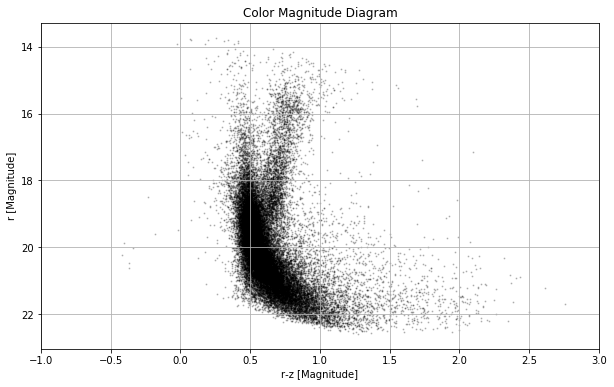

In [7]:
plt.figure(figsize = (10,6))
plt.tight_layout()

plt.scatter(rmz, r, s=1, color = 'k', alpha = 0.2)

plt.gca().invert_yaxis() # Flips the y-axis --> normal for cmds
plt.xlim(-1, 3)

plt.title('Color Magnitude Diagram')
plt.xlabel('r-z [Magnitude]')
plt.ylabel('r [Magnitude]')
plt.grid(True)

plt.show()

/usr/local/anaconda-python3.7-conda4.5/lib/python3.7/site-packages/scipy/stats/_binned_statistic.py:607: FutureWarning: Using a non-tuple sequence for multidimensional indexing is deprecated; use `arr[tuple(seq)]` instead of `arr[seq]`. In the future this will be interpreted as an array index, `arr[np.array(seq)]`, which will result either in an error or a different result.
  result = result[core]


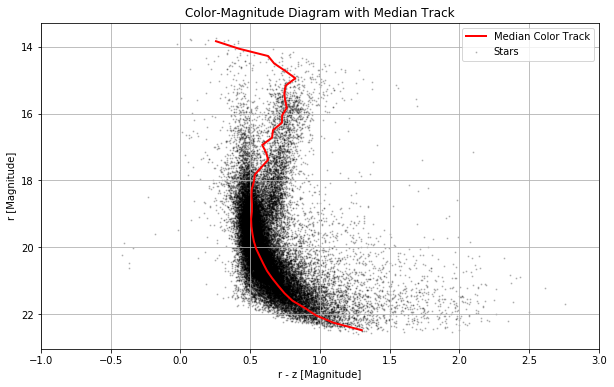

In [8]:
from scipy.stats import binned_statistic # calculates statistics (like mean, median, std) over bins of a given data range

# Bin CMD by magnitude
bins = 40 # divide the magnitude range into 40 equal-width intervals
bin_edges = np.linspace(r.min(), r.max(), bins + 1) # creates an array of evenly spaced values from r.min() to r.max(), with bins + 1 points
bin_centers = 0.5 * (bin_edges[1:] + bin_edges[:-1]) # takes the average of the lower and upper edge of each bin

med_color, _, _ = binned_statistic(r, rmz, statistic='median', bins=bin_edges) # calculates the median color (r - z, stored in rmz) within each bin of magnitude r
# the underscores are unused outputs: one is the bin number for each input point, and one is the bin edges

# Plot CMD and trend
plt.figure(figsize=(10, 6))
plt.tight_layout()

plt.scatter(rmz, r, s=1, alpha=0.2, color='black', label='Stars')
plt.plot(med_color, bin_centers, color='red', lw=2, label='Median Color Track')

plt.gca().invert_yaxis()
plt.xlim(-1, 3)

plt.xlabel('r - z [Magnitude]')
plt.ylabel('r [Magnitude]')
plt.title('Color-Magnitude Diagram with Median Track')
plt.legend()
plt.grid(True)

plt.show()

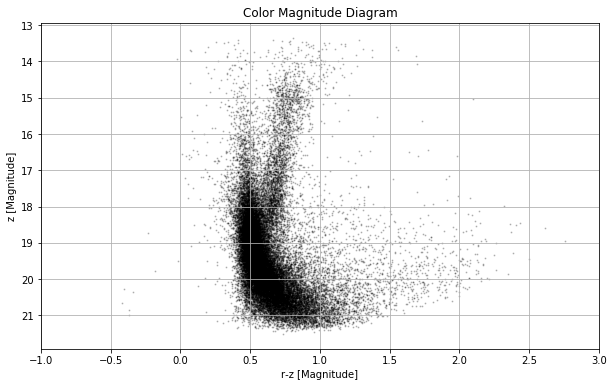

In [9]:
plt.figure(figsize = (10,6))
plt.tight_layout()

plt.scatter(rmz, z, s=1, color = 'k', alpha = 0.2)

plt.gca().invert_yaxis() # Flips the y-axis --> normal for cmds
plt.xlim(-1, 3)

plt.title('Color Magnitude Diagram')
plt.xlabel('r-z [Magnitude]')
plt.ylabel('z [Magnitude]')
plt.grid(True)

plt.show()

/usr/local/anaconda-python3.7-conda4.5/lib/python3.7/site-packages/scipy/stats/_binned_statistic.py:607: FutureWarning: Using a non-tuple sequence for multidimensional indexing is deprecated; use `arr[tuple(seq)]` instead of `arr[seq]`. In the future this will be interpreted as an array index, `arr[np.array(seq)]`, which will result either in an error or a different result.
  result = result[core]


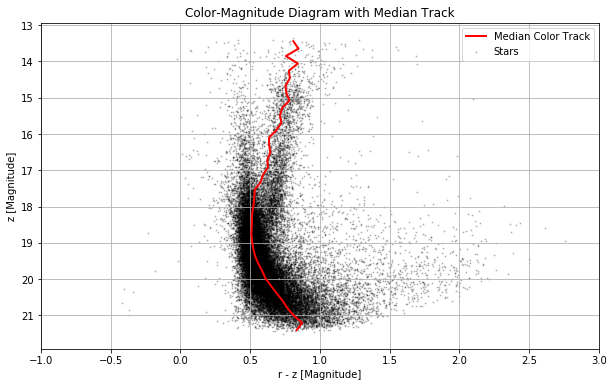

In [11]:
# Bin CMD by magnitude
num_bins = 40
bin_edgez = np.linspace(z.min(), z.max(), num_bins + 1)
bin_centerz = 0.5 * (bin_edgez[1:] + bin_edgez[:-1])

med_colorz, _, _ = binned_statistic(z, rmz, statistic='median', bins=bin_edgez)

# Plot CMD and trend
plt.figure(figsize=(10, 6))
plt.tight_layout()

plt.scatter(rmz, z, s=1, alpha=0.2, color='black', label='Stars')
plt.plot(med_colorz, bin_centerz, color='red', lw=2, label='Median Color Track')

plt.gca().invert_yaxis()
plt.xlim(-1, 3)

plt.xlabel('r - z [Magnitude]')
plt.ylabel('z [Magnitude]')
plt.title('Color-Magnitude Diagram with Median Track')
plt.legend()
plt.grid(True)

plt.show()

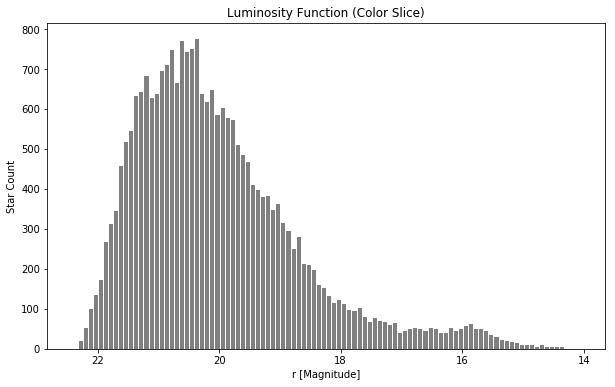

In [13]:
# Select a color slice that brackets the main feature
color_mask = (rmz > 0.5) & (rmz < 1.0)
r_slice = r[color_mask]

# Plot histogram to find peak
plt.figure(figsize = (10,6))
plt.tight_layout()

plt.hist(r_slice, bins = 100, color = 'grey', edgecolor = 'white')

plt.gca().invert_xaxis()
plt.xlabel('r [Magnitude]')
plt.ylabel('Star Count')
plt.title('Luminosity Function (Color Slice)')

plt.show()

Gaussian fit peak: 20.444 mag, σ = 1.103


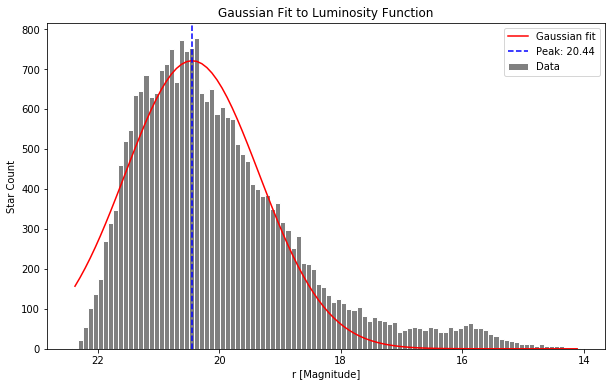

In [14]:
# Fit a gaussian to determine peak magnitude
counts, bin_edges = np.histogram(r_slice, bins = 100)
peak_index = np.argmax(counts)
peak_mag = (bin_edges[peak_index] + bin_edges[peak_index + 1]) / 2


#print(f"Estimated peak magnitude: {peak_mag:.3f}")

# Gaussian function
def gauss(x, A, mu, sigma):
    return A * np.exp(-(x - mu)**2 / (2 * sigma**2))

# Bin centers
bin_centers = (bin_edges[:-1] + bin_edges[1:]) / 2

# Initial guess: amplitude, mean, sigma
p0 = [np.max(counts), peak_mag, 0.2]

# Fit
popt, _ = curve_fit(gauss, bin_centers, counts, p0=p0)

# Extract fitted parameters
A_fit, mu_fit, sigma_fit = popt
print(f"Gaussian fit peak: {mu_fit:.3f} mag, σ = {sigma_fit:.3f}")

# Plot histogram
plt.figure(figsize = (10,6))
plt.tight_layout()

plt.hist(r_slice, bins = 100, color = 'grey', edgecolor = 'white', label = 'Data')
plt.plot(bin_centers, gauss(bin_centers, *popt), 'r-', label = 'Gaussian fit')

plt.gca().invert_xaxis()
plt.axvline(mu_fit, color = 'blue', linestyle = '--', label = f'Peak: {mu_fit:.2f}')

plt.xlabel('r [Magnitude]')
plt.ylabel('Star Count')
plt.title('Gaussian Fit to Luminosity Function')

plt.legend(loc = 'best')
plt.show()

# code example: Google AI (Search gaussian fit python) and 
 # https://docs.scipy.org/doc/scipy/reference/generated/scipy.optimize.curve_fit.html

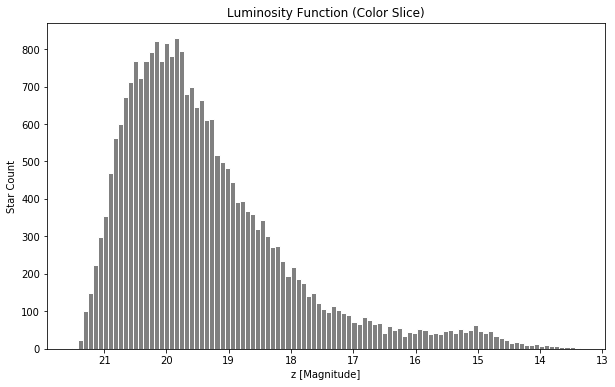

In [17]:
# Select a color slice that brackets the main feature
color_mask = (rmz > 0.5) & (rmz < 1.0)
z_slice = z[color_mask]

# Plot histogram to find peak
plt.figure(figsize = (10,6))
plt.tight_layout()

plt.hist(z_slice, bins = 100, color = 'grey', edgecolor = 'white')

plt.gca().invert_xaxis()
plt.xlabel('z [Magnitude]')
plt.ylabel('Star Count')
plt.title('Luminosity Function (Color Slice)')

plt.show()

Gaussian fit peak: 19.858 mag, σ = 0.981


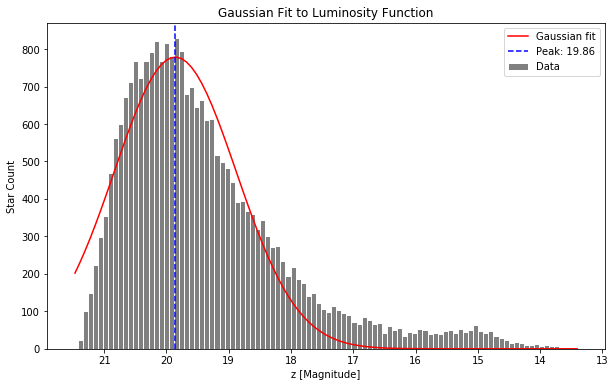

In [18]:
# Fit a gaussian to determine peak magnitude
counts, bin_edges = np.histogram(z_slice, bins = 100)
peak_index = np.argmax(counts)
peak_mag = (bin_edges[peak_index] + bin_edges[peak_index + 1]) / 2

# Bin centers
bin_centers = (bin_edges[:-1] + bin_edges[1:]) / 2

# Initial guess: amplitude, mean, sigma
p0 = [np.max(counts), peak_mag, 0.2]

# Fit
popt, _ = curve_fit(gauss, bin_centers, counts, p0=p0)

# Extract fitted parameters
A_fit, mu_fit, sigma_fit = popt
print(f"Gaussian fit peak: {mu_fit:.3f} mag, σ = {sigma_fit:.3f}")

# Plot histogram 
plt.figure(figsize = (10,6))
plt.tight_layout()

plt.hist(z_slice, bins = 100, color = 'grey', edgecolor = 'white', label = 'Data')
plt.plot(bin_centers, gauss(bin_centers, *popt), 'r-', label = 'Gaussian fit')

plt.gca().invert_xaxis()
plt.axvline(mu_fit, color = 'blue', linestyle = '--', label = f'Peak: {mu_fit:.2f}')

plt.xlabel('z [Magnitude]')
plt.ylabel('Star Count')
plt.title('Gaussian Fit to Luminosity Function')

plt.legend(loc = 'best')
plt.show()